# Lista de Exercícios 1 - Advanced Econometrics (2026)

Mestrado Profissional em Economia, Insper. Prof. Hedibert Freitas Lopes.

**Group:** (names)

**Data.** Monthly number of motorcycle-rider deaths in the city of São Paulo, January 2015 to August 2026, $n = 140$ months (INFOSIGA-SP/DETRAN-SP, victim microdata, version of 16/09/2026). $y_t$ is the number of deaths in month $t$, with $t = 1$ for January 2015.

**How to read this report.** Each question starts with a heading "Question k". The answer to each item is in the cell headed "Answer k(x)", and its first line gives the result. The code that produces each number sits right above the answer. A summary table of all answers is at the end. Code in Python (numpy, pandas, scipy, statsmodels, matplotlib).

## Setup and data

The table printed below has the same layout as the table in the statement and was used to check the data entry (first value 21 in Jan 2015, last value 47 in Aug 2026).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, poisson, chi2, t
from scipy.optimize import minimize
import statsmodels.api as sm

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
y = np.array([21,28,33,38,35,39,27,24,24,26,22,38, 23,26,30,36,22,21,16,28,23,20,22,39,
              16,21,27,31,25,31,31,16,20,24,22,32, 26,23,22,40,23,29,32,24,28,24,25,51,
              32,19,19,16,26,22,24,35,29,34,14,27, 19,19,38,17,40,13,21,26,32,16,24,27,
              33,23,19,18,25,28,30,28,34,31,27,17, 29,19,38,32,40,38,30,35,40,46,32,37,
              27,19,40,25,26,28,42,31,34,38,39,54, 38,28,43,42,38,50,44,38,41,44,28,56,
              31,33,39,31,49,39,46,46,50,36,25,54, 31,34,41,40,43,50,48,47])
n = len(y)
dates = pd.date_range("2015-01", periods=n, freq="MS")
ys = pd.Series(y, index=dates, name="deaths")
t_idx = np.arange(1, n + 1)

assert n == 140 and y[0] == 21 and y[-1] == 47

# same layout as the table in the PDF, to check the data entry
tab = ys.to_frame().assign(year=dates.year, month=dates.month).pivot(index="year", columns="month", values="deaths").astype("Int64")
tab

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2015,21,28,33,38,35,39,27,24,24,26,22,38
2016,23,26,30,36,22,21,16,28,23,20,22,39
2017,16,21,27,31,25,31,31,16,20,24,22,32
2018,26,23,22,40,23,29,32,24,28,24,25,51
2019,32,19,19,16,26,22,24,35,29,34,14,27
2020,19,19,38,17,40,13,21,26,32,16,24,27
2021,33,23,19,18,25,28,30,28,34,31,27,17
2022,29,19,38,32,40,38,30,35,40,46,32,37
2023,27,19,40,25,26,28,42,31,34,38,39,54


---
## Question 1: Histogram

*Histogram of $y_1,\dots,y_n$; comment on shape, typical values, dispersion and possible outliers; report the sample mean, median, variance and standard deviation.*

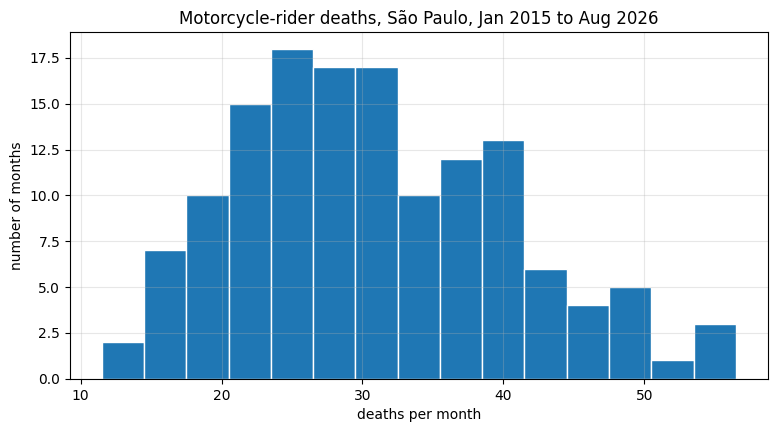

n                     140.000
mean                   30.914
median                 30.000
variance (ddof=1)      92.252
std. dev. (ddof=1)      9.605
min                    13.000
Q1                     24.000
Q3                     38.000
max                    56.000
skewness                0.442
excess kurtosis        -0.438

1.5*IQR fences: [3.0, 59.0]; months outside: {}
five highest months: {'2024-12': 56, '2023-12': 54, '2025-12': 54, '2018-12': 51, '2024-06': 50}
five lowest months:  {'2020-06': 13, '2019-11': 14, '2016-07': 16, '2017-01': 16, '2017-08': 16}


In [3]:
bins = np.arange(11.5, 59.5, 3)  # width-3 bins centred on integers
fig, ax = plt.subplots()
ax.hist(y, bins=bins, edgecolor="white")
ax.set_xlabel("deaths per month")
ax.set_ylabel("number of months")
ax.set_title("Motorcycle-rider deaths, São Paulo, Jan 2015 to Aug 2026")
plt.show()

q1, q3 = np.percentile(y, [25, 75])
desc = pd.Series({
    "n": n,
    "mean": y.mean(),
    "median": np.median(y),
    "variance (ddof=1)": y.var(ddof=1),
    "std. dev. (ddof=1)": y.std(ddof=1),
    "min": y.min(), "Q1": q1, "Q3": q3, "max": y.max(),
    "skewness": stats.skew(y),
    "excess kurtosis": stats.kurtosis(y),
})
print(desc.round(3).to_string())

lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"\n1.5*IQR fences: [{lo:.1f}, {hi:.1f}]; months outside:", ys[(ys < lo) | (ys > hi)].to_dict())
print("five highest months:", ys.nlargest(5).rename(lambda d: d.strftime("%Y-%m")).to_dict())
print("five lowest months: ", ys.nsmallest(5).rename(lambda d: d.strftime("%Y-%m")).to_dict())

### Answer 1

**Result:** mean $= 30.91$, median $= 30$, variance $= 92.25$, standard deviation $= 9.60$ (variance and s.d. with denominator $n-1$). Minimum 13, maximum 56, quartiles 24 and 38.

- Shape: One broad peak between 22 and 33 deaths, then a second, smaller group of months around 37 to 42. The right tail is longer than the left: the distribution is mildly right-skewed (skewness 0.44, mean slightly above the median). Tails are lighter than in a normal (excess kurtosis $-0.44$); the histogram is flat rather than bell-shaped.
- Typical values: Half of the months have between 24 and 38 deaths; the centre is about 30 deaths per month.
- Dispersion: The s.d. of 9.6 is about 31% of the mean, and the variance (92.3) is three times the mean. This matters for the Poisson model in Question 3.
- Outliers: No month falls outside the $1.5\times$IQR fences $[3, 59]$, so there are no outliers in the boxplot sense. The highest values are all Decembers (Dec 2024: 56; Dec 2023 and Dec 2025: 54; Dec 2018: 51), and the lowest are scattered in 2016 to 2020 (Jun 2020: 13; Nov 2019: 14). Question 4 shows that the high months belong to the end of the sample, so the flat, two-group shape of the histogram is already a sign that the level of the series changed over time.

---
## Question 2: Gaussian model, $y_t \mid \mu,\sigma^2 \sim N(\mu,\sigma^2)$ i.i.d.

*(a) Likelihood and MLEs of $\mu$ and $\sigma^2$. (b) Estimates and 95% CI for $\mu$. (c) Normal density over the histogram; quality of fit; what the Gaussian model ignores.*

### Answer 2(a)

**Result:** $\hat\mu = \bar y$ and $\hat\sigma^2 = \frac{1}{n}\sum_{t=1}^n (y_t-\bar y)^2$.

Likelihood:
$$L(\mu,\sigma^2; y) = \prod_{t=1}^n \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left\{-\frac{(y_t-\mu)^2}{2\sigma^2}\right\} = (2\pi\sigma^2)^{-n/2}\exp\left\{-\frac{1}{2\sigma^2}\sum_{t=1}^n (y_t-\mu)^2\right\}.$$

Log-likelihood:
$$\ell(\mu,\sigma^2) = -\frac{n}{2}\log(2\pi) - \frac{n}{2}\log\sigma^2 - \frac{1}{2\sigma^2}\sum_{t=1}^n (y_t-\mu)^2.$$

Score for $\mu$:
$$\frac{\partial \ell}{\partial \mu} = \frac{1}{\sigma^2}\sum_{t=1}^n (y_t-\mu) = 0 \;\Longrightarrow\; \sum_{t=1}^n y_t = n\mu \;\Longrightarrow\; \hat\mu = \bar y.$$

Score for $\sigma^2$:
$$\frac{\partial \ell}{\partial \sigma^2} = -\frac{n}{2\sigma^2} + \frac{1}{2\sigma^4}\sum_{t=1}^n (y_t-\mu)^2 = 0 \;\Longrightarrow\; \hat\sigma^2 = \frac{1}{n}\sum_{t=1}^n (y_t-\hat\mu)^2.$$

Second-order check at $(\hat\mu,\hat\sigma^2)$: $\partial^2\ell/\partial\mu^2 = -n/\hat\sigma^2$, $\partial^2\ell/\partial(\sigma^2)^2 = n/(2\hat\sigma^4) - n\hat\sigma^2/\hat\sigma^6 = -n/(2\hat\sigma^4)$ and the cross derivative $-\sum(y_t-\hat\mu)/\hat\sigma^4 = 0$. The Hessian is diagonal with negative entries, so the stationary point is a maximum.

The MLE $\hat\sigma^2$ divides by $n$ and is biased; the unbiased $s^2$ divides by $n-1$. Below, $\hat\sigma^2$ (ddof = 0) is used for the fitted density and the log-likelihood, and $s$ (ddof = 1) for the $t$ interval.

In [4]:
mu_hat = y.mean()
sigma2_hat = y.var(ddof=0)   # MLE divides by n
s = y.std(ddof=1)            # unbiased s^2 divides by n-1; used in the t interval
t_q = t.ppf(0.975, n - 1)
ci_mu = (mu_hat - t_q * s / np.sqrt(n), mu_hat + t_q * s / np.sqrt(n))

pd.Series({"mu_hat": mu_hat, "sigma2_hat (MLE, /n)": sigma2_hat, "s^2 (/(n-1))": s**2,
           "sigma_hat": np.sqrt(sigma2_hat), "t_0.975,139": t_q,
           "95% CI lower": ci_mu[0], "95% CI upper": ci_mu[1]}).round(3).to_frame("Gaussian model")

,Gaussian model
mu_hat,30.914
"sigma2_hat (MLE, /n)",91.593
s^2 (/(n-1)),92.252
sigma_hat,9.570
"t_0.975,139",1.977
95% CI lower,29.309
95% CI upper,32.519


### Answer 2(b)

**Result:** $\hat\mu = 30.91$, $\hat\sigma^2 = 91.59$ ($\hat\sigma = 9.57$; the unbiased $s^2 = 92.25$). The 95% CI for $\mu$ is $[29.31,\ 32.52]$.

Interval used: $\bar y \pm t_{0.975,\,n-1}\, s/\sqrt n = 30.91 \pm 1.977 \times 9.605/\sqrt{140}$. With $n = 140$ the normal quantile 1.96 gives practically the same interval.

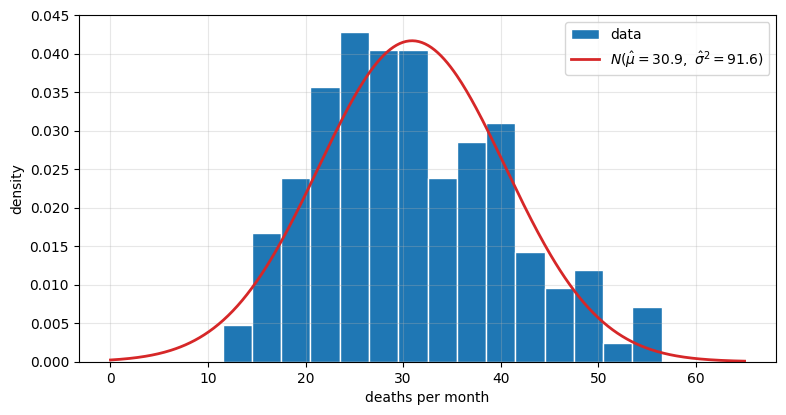

P(Y < 0) under the fitted normal = 6.2e-04
Shapiro-Wilk: W = 0.973, p = 0.007


In [5]:
grid = np.linspace(0, 65, 400)
fig, ax = plt.subplots()
ax.hist(y, bins=bins, density=True, edgecolor="white", label="data")
ax.plot(grid, norm.pdf(grid, mu_hat, np.sqrt(sigma2_hat)), lw=2, color="C3",
        label=rf"$N(\hat\mu={mu_hat:.1f},\ \hat\sigma^2={sigma2_hat:.1f})$")
ax.set_xlabel("deaths per month")
ax.set_ylabel("density")
ax.legend()
plt.show()

sw = stats.shapiro(y)
print(f"P(Y < 0) under the fitted normal = {norm.cdf(0, mu_hat, np.sqrt(sigma2_hat)):.1e}")
print(f"Shapiro-Wilk: W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")

### Answer 2(c)

**Result:** the fit is only rough. The normal matches the centre and spread of the data, but not the shape: the data have more months than predicted between 18 and 26 deaths (43 against 33.8 expected), fewer around 33 to 35 (10 against 16.6), and more at the top end, 48 to 56 (9 against 5.4). The data are flatter and more skewed than the bell curve, and the Shapiro-Wilk test rejects normality ($W = 0.973$, $p = 0.007$).

What the Gaussian model ignores about these data:
1. They are counts: $y_t$ only takes non-negative integer values; the normal is continuous and gives positive probability to negative values (small here, $P(Y<0) = 6\times10^{-4}$, but not zero).
2. Mean and variance are tied for counts: For a count process the variance usually grows with the level; the normal has a free $\sigma^2$ that does not depend on $\mu$.
3. Asymmetry: Counts are right-skewed, and so are these data; the normal is symmetric.
4. Time: The model treats the 140 months as i.i.d. draws, so it ignores trend, the level shift around 2022, December seasonality and autocorrelation (Question 4). Most of the misfit comes from this: the histogram mixes months from a low-level period and a high-level period.

---
## Question 3: Poisson model, $y_t \mid \lambda \sim \text{Poisson}(\lambda)$ independent

*(a) Show that $\hat\lambda = \bar y$ and get its asymptotic standard error. (b) Estimate and 95% CI. (c) Observed frequencies vs $p(y\mid\hat\lambda)$. (d) Mean vs variance: overdispersion? (e) Compare the Gaussian and Poisson fits.*

### Answer 3(a)

**Result:** $\hat\lambda = \bar y$, with asymptotic standard error $\text{se}(\hat\lambda) = \sqrt{\hat\lambda/n}$.

Likelihood and log-likelihood:
$$L(\lambda; y) = \prod_{t=1}^n \frac{\lambda^{y_t}e^{-\lambda}}{y_t!}, \qquad \ell(\lambda) = \left(\sum_{t=1}^n y_t\right)\log\lambda - n\lambda - \sum_{t=1}^n \log y_t!.$$

Score:
$$\ell'(\lambda) = \frac{\sum_t y_t}{\lambda} - n = 0 \;\Longrightarrow\; \hat\lambda = \frac{1}{n}\sum_{t=1}^n y_t = \bar y.$$

Second derivative: $\ell''(\lambda) = -\sum_t y_t/\lambda^2 < 0$ (if $\sum_t y_t > 0$), so $\bar y$ is the maximum.

Fisher information:
$$I(\lambda) = E[-\ell''(\lambda)] = \frac{E\left(\sum_t y_t\right)}{\lambda^2} = \frac{n\lambda}{\lambda^2} = \frac{n}{\lambda}.$$

By the asymptotic normality of the MLE, $\hat\lambda \overset{a}{\sim} N\left(\lambda,\ I(\lambda)^{-1}\right) = N(\lambda,\ \lambda/n)$, so $\text{se}(\hat\lambda) = \sqrt{\hat\lambda/n}$. (Here the variance is also exact: $V(\bar y) = \lambda/n$.)

In [6]:
lam_hat = y.mean()
se_lam = np.sqrt(lam_hat / n)
ci_lam = (lam_hat - 1.96 * se_lam, lam_hat + 1.96 * se_lam)

pd.Series({"lambda_hat": lam_hat, "se = sqrt(lambda_hat/n)": se_lam,
           "95% CI lower": ci_lam[0], "95% CI upper": ci_lam[1]}).round(3).to_frame("Poisson model")

,Poisson model
lambda_hat,30.914
se = sqrt(lambda_hat/n),0.470
95% CI lower,29.993
95% CI upper,31.835


### Answer 3(b)

**Result:** $\hat\lambda = 30.91$, $\text{se} = \sqrt{30.91/140} = 0.47$, 95% Wald CI $= 30.91 \pm 1.96 \times 0.47 = [29.99,\ 31.84]$.

This interval is about half as wide as the Gaussian one in 2(b), $[29.31,\ 32.52]$, even though both are centred at $\bar y$. The Poisson interval assumes $V(y_t) = \lambda \approx 31$, while the sample variance is 92. Item 3(d) shows the Poisson assumption is wrong here, so this interval is too narrow.

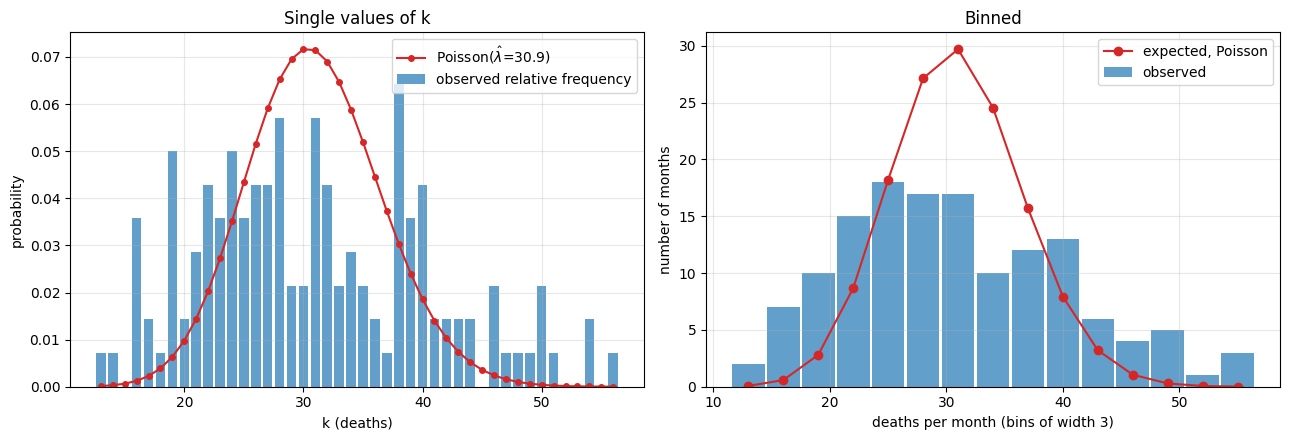

,observed,Poisson
P(y <= 20),0.136,0.025
P(21 <= y <= 41),0.729,0.942
P(y >= 42),0.136,0.033


In [7]:
k = np.arange(y.min(), y.max() + 1)
obs_freq = np.array([(y == kk).mean() for kk in k])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(k, obs_freq, color="C0", alpha=0.7, label="observed relative frequency")
axes[0].plot(k, poisson.pmf(k, lam_hat), "o-", color="C3", ms=4,
             label=rf"Poisson($\hat\lambda$={lam_hat:.1f})")
axes[0].set_xlabel("k (deaths)")
axes[0].set_ylabel("probability")
axes[0].set_title("Single values of k")
axes[0].legend()

# same width-3 bins as the histogram: observed counts vs expected counts n * P(bin)
obs_bin, _ = np.histogram(y, bins=bins)
exp_pois = n * np.diff(poisson.cdf(np.floor(bins), lam_hat))
mids = (bins[:-1] + bins[1:]) / 2
axes[1].bar(mids, obs_bin, width=2.8, color="C0", alpha=0.7, label="observed")
axes[1].plot(mids, exp_pois, "o-", color="C3", label="expected, Poisson")
axes[1].set_xlabel("deaths per month (bins of width 3)")
axes[1].set_ylabel("number of months")
axes[1].set_title("Binned")
axes[1].legend()
plt.tight_layout()
plt.show()

tails = pd.DataFrame({
    "observed": [(y <= 20).mean(), ((y > 20) & (y < 42)).mean(), (y >= 42).mean()],
    "Poisson": [poisson.cdf(20, lam_hat), poisson.cdf(41, lam_hat) - poisson.cdf(20, lam_hat),
                poisson.sf(41, lam_hat)],
}, index=["P(y <= 20)", "P(21 <= y <= 41)", "P(y >= 42)"])
tails.round(3)

### Answer 3(c)

**Result:** the Poisson distribution is much too concentrated around the mean. It underpredicts both tails and overpredicts the centre.

| | observed | Poisson($\hat\lambda = 30.91$) |
|---|---|---|
| $P(y \le 20)$ | 0.136 | 0.025 |
| $P(21 \le y \le 41)$ | 0.729 | 0.942 |
| $P(y \ge 42)$ | 0.136 | 0.033 |

In the binned plot, the Poisson expects 27 to 30 months in each of the bins 27-29 and 30-32 and 25 months in 33-35; the data have 17, 17 and 10. At the extremes it expects 0.7 months at or below 17 deaths and 1.4 months at or above 45; the data have 9 and 13. The Poisson predicts 4.6 months at or above 42 deaths, against 19 observed.

In [8]:
ybar, s2 = y.mean(), y.var(ddof=1)
D = np.sum((y - ybar) ** 2) / ybar   # ~ chi2(n-1) under the Poisson model
pd.Series({"mean": ybar, "variance (ddof=1)": s2, "variance/mean": s2 / ybar,
           "dispersion statistic D": D, "df": n - 1,
           "p-value P(chi2_139 > D)": chi2.sf(D, n - 1)}).to_frame("dispersion check").map(lambda v: f"{v:.4g}")

,dispersion check
mean,30.91
variance (ddof=1),92.25
variance/mean,2.984
dispersion statistic D,414.8
df,139
p-value P(chi2_139 > D),3.087e-29


### Answer 3(d)

**Result:** yes, strong overdispersion. Sample mean $= 30.91$ and sample variance $= 92.25$, so variance/mean $= 2.98$, while the Poisson model requires a ratio of 1. The dispersion statistic $D = \sum_t (y_t-\bar y)^2/\bar y = 414.8$ is compared with a $\chi^2_{139}$ (mean 139): $p \approx 3\times10^{-29}$.

What this means for the model:
- The Poisson model with a single constant $\lambda$ does not describe the data: the months vary about three times more than a Poisson allows.
- $\hat\lambda = \bar y$ is still a reasonable estimate of the mean, but its standard error $\sqrt{\hat\lambda/n} = 0.47$ is too small by a factor of about $\sqrt{2.98} = 1.73$. A standard error based on the sample variance is $\sqrt{92.25/140} = 0.81$. The CI in 3(b) and any Poisson-based test overstate precision.
- Overdispersion usually means the rate is not the same in every month (heterogeneity). Here the time series plot (Question 4) gives the reason: the rate changes over time and with the season. Two ways forward are to let $\lambda$ vary (Questions 5 and 6) or to use a model with extra variance, such as the negative binomial.

In [9]:
ll_norm = norm.logpdf(y, mu_hat, np.sqrt(sigma2_hat)).sum()
ll_pois = poisson.logpmf(y, lam_hat).sum()
# Gaussian turned into a pmf on the integers, P(k-0.5 < Y < k+0.5): checks the density-vs-pmf caveat
ll_norm_disc = np.log(norm.cdf(y + 0.5, mu_hat, np.sqrt(sigma2_hat))
                      - norm.cdf(y - 0.5, mu_hat, np.sqrt(sigma2_hat))).sum()

fit = pd.DataFrame({"k (parameters)": [2, 1, 2],
                    "max log-lik": [ll_norm, ll_pois, ll_norm_disc]},
                   index=["Gaussian (density)", "Poisson", "Gaussian discretised"])
fit["AIC"] = -2 * fit["max log-lik"] + 2 * fit["k (parameters)"]
fit.round(2)

,k (parameters),max log-lik,AIC
Gaussian (density),2,-514.87,1033.73
Poisson,1,-571.51,1145.03
Gaussian discretised,2,-514.87,1033.73


### Answer 3(e)

**Result:** the Gaussian model fits better. Maximized log-likelihood: Gaussian $-514.87$ ($k = 2$), Poisson $-571.51$ ($k = 1$). AIC: Gaussian $1033.7$, Poisson $1145.0$. The AIC difference of 111 points is very large, so the Gaussian is preferred even with one more parameter.

Caveat: the Gaussian log-likelihood uses a density and the Poisson one uses probabilities, so in principle they are not on the same scale. To check this, the normal was turned into a distribution on the integers, $P(k-0.5 < Y < k+0.5)$. Its log-likelihood is also $-514.87$: with $\hat\sigma \approx 9.6$ the density is almost constant over an interval of length 1, so the comparison is valid here.

The reason the Gaussian wins is not that the data are normal (2(c) shows they are not). It wins because it has a free variance parameter that can absorb the overdispersion, while the Poisson is forced to have variance 30.9. Neither model is adequate, since both ignore the time structure.

---
## Question 4: Time series plot

*Plot $y_t$ against time and comment on level, trend, seasonality, regime changes and atypical months. Discuss the i.i.d. assumption of Questions 2 and 3.*

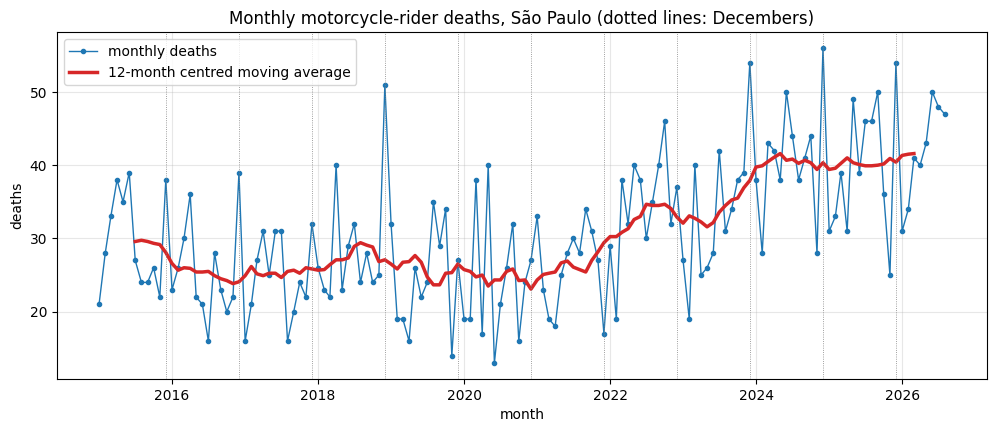

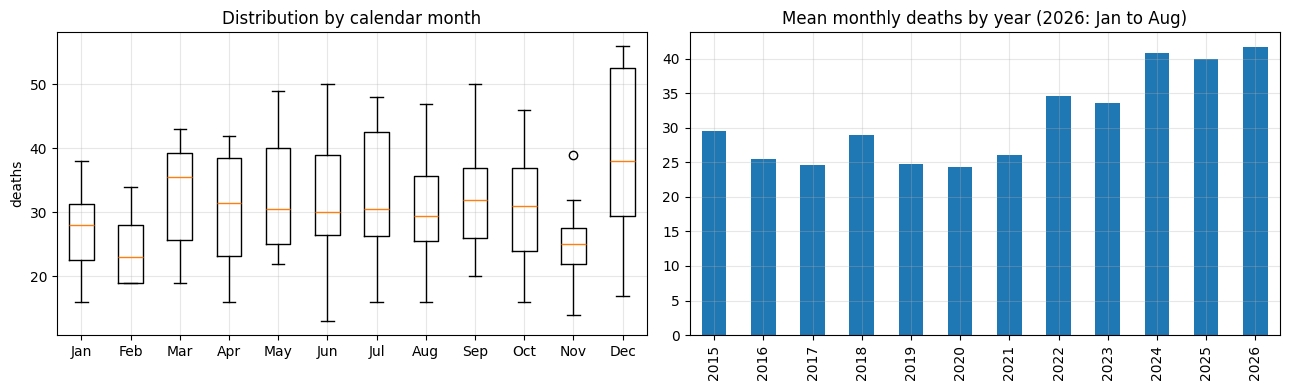

mean by year:
 2015    29.6
2016    25.5
2017    24.7
2018    28.9
2019    24.8
2020    24.3
2021    26.1
2022    34.7
2023    33.6
2024    40.8
2025    39.9
2026    41.8

mean by calendar month:
 1     27.2
2     24.3
3     32.4
4     30.5
5     32.7
6     32.3
7     32.6
8     31.5
9     32.3
10    30.8
11    25.5
12    39.3

lag-1 autocorrelation = 0.375  (approx. 95% band under i.i.d.: ±0.166)


In [10]:
ma12 = ys.rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ys.index, ys, "o-", ms=3, lw=1, label="monthly deaths")
ax.plot(ma12.index, ma12, lw=2.5, color="C3", label="12-month centred moving average")
for d in ys[ys.index.month == 12].index:
    ax.axvline(d, color="grey", lw=0.6, ls=":")
ax.set_xlabel("month")
ax.set_ylabel("deaths")
ax.set_title("Monthly motorcycle-rider deaths, São Paulo (dotted lines: Decembers)")
ax.legend(loc="upper left")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_month = [ys[ys.index.month == m].values for m in range(1, 13)]
axes[0].boxplot(by_month, tick_labels=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
axes[0].set_title("Distribution by calendar month")
axes[0].set_ylabel("deaths")
ys.groupby(ys.index.year).mean().plot.bar(ax=axes[1], color="C0")
axes[1].set_title("Mean monthly deaths by year (2026: Jan to Aug)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

print("mean by year:\n", ys.groupby(ys.index.year).mean().round(1).to_string())
print("\nmean by calendar month:\n", ys.groupby(ys.index.month).mean().round(1).to_string())
r1 = np.corrcoef(y[:-1], y[1:])[0, 1]
print(f"\nlag-1 autocorrelation = {r1:.3f}  (approx. 95% band under i.i.d.: ±{1.96/np.sqrt(n):.3f})")

### Answer 4

**Result:** the series is not i.i.d. The level is roughly flat at 25 to 30 deaths per month from 2015 to 2021, rises sharply in 2022, and keeps rising until about 40 per month in 2024 to 2026. There is also a clear December peak and positive autocorrelation.

- Level and trend: Annual means: 29.6 (2015), then 24 to 29 from 2016 to 2021, 34.7 (2022), 33.6 (2023), 40.8 (2024), 39.9 (2025) and 41.8 (2026, Jan to Aug). The 12-month moving average is flat (slightly falling) until 2021 and then climbs from about 26 to about 41 between late 2021 and early 2024. After 2024 it is flat again at a higher level.
- Regime change: The change happens around the turn of 2021 to 2022. The level in the second part is about 45% higher than in the first.
- Seasonality: December is the worst month in most years (mean 39.3, against 30.9 overall): 51 in Dec 2018, 54 in Dec 2023, 56 in Dec 2024 and 54 in Dec 2025. February (24.3), November (25.5) and January (27.2) are the lowest months on average.
- Atypical months: Dec 2021 (17) is an unusually low December. 2020 is very irregular (40 in May and 13 in June, the lowest value of the series), which coincides with the pandemic period. Nov 2025 (25) is low compared with its neighbours.
- Dependence: The lag-1 autocorrelation is 0.375, well outside the band $\pm 0.166$ expected under independence.

**i.i.d. assumption.** Questions 2 and 3 assume every month comes from the same distribution, independently. The plot contradicts both parts: the mean changes over time (not identically distributed), and nearby months are similar (not independent). Pooling all 140 months mixes a low regime and a high regime, which explains the flat, two-group histogram of Question 1 and a large part of the overdispersion found in 3(d).

---
## Question 5: Structural break at $\tau$

*Choose $\tau$, split the sample into Part 1 ($t \le \tau$) and Part 2 ($t > \tau$). (a) Normal models in each part. (b) Poisson models in each part. (c) CIs and tests of $H_0: \mu_1 = \mu_2$ and $H_0: \lambda_1 = \lambda_2$. (d) Is the break confirmed? Sensitivity to $\tau$. (e) Mean vs variance within each part.*

In [11]:
tau = 84   # Part 1 = Jan 2015 to Dec 2021 (84 months), Part 2 = Jan 2022 to Aug 2026
y1, y2 = y[:tau], y[tau:]
n1, n2 = len(y1), len(y2)
print(f"tau = {tau}: last month of Part 1 = {dates[tau-1]:%Y-%m}, first month of Part 2 = {dates[tau]:%Y-%m}")
print(f"n1 = {n1}, n2 = {n2}")

tau = 84: last month of Part 1 = 2021-12, first month of Part 2 = 2022-01
n1 = 84, n2 = 56


### Choice of $\tau$

**Choice:** $\tau = 84$, so Part 1 is January 2015 to December 2021 (84 months) and Part 2 is January 2022 to August 2026 (56 months).

Reasons:
1. In the plot of Question 4 the annual means are between 24 and 30 for every year up to 2021 and at least 33.6 for every year from 2022 on. The moving average starts to rise at the end of 2021.
2. Cutting at the end of a calendar year means Part 1 has seven complete years, so every calendar month (including the December peak) appears the same number of times in Part 1, and the seasonal pattern does not bias the Part 1 mean.
3. As a check (computed in 5(d)), the Poisson profile log-likelihood over all possible break points is maximized at $\tau = 86$ (February 2022), only two months away from our choice.

In [12]:
def normal_mle(x):
    """MLE of (mu, sigma^2) for an i.i.d. normal sample (variance with ddof=0)."""
    return x.mean(), x.var(ddof=0)


def ll_normal(x):
    """Maximised normal log-likelihood of sample x."""
    m, v = normal_mle(x)
    return norm.logpdf(x, m, np.sqrt(v)).sum()


def ll_poisson(x, lam=None):
    """Poisson log-likelihood of sample x at lam (default: the MLE, the sample mean)."""
    return poisson.logpmf(x, x.mean() if lam is None else lam).sum()


mu1, s2_1 = normal_mle(y1)
mu2, s2_2 = normal_mle(y2)
lam1, lam2 = y1.mean(), y2.mean()

pd.DataFrame({"Part 1 (2015-01 to 2021-12)": [n1, mu1, s2_1, lam1],
              "Part 2 (2022-01 to 2026-08)": [n2, mu2, s2_2, lam2],
              "No break (items 2-3)": [n, mu_hat, sigma2_hat, lam_hat]},
             index=["n", "mu_hat", "sigma2_hat (MLE)", "lambda_hat"]).round(3)

,Part 1 (2015-01 to 2021-12),Part 2 (2022-01 to 2026-08),No break (items 2-3)
n,84.000,56.000,140.000
mu_hat,26.262,37.893,30.914
sigma2_hat (MLE),50.193,72.524,91.593
lambda_hat,26.262,37.893,30.914


### Answer 5(a) and 5(b)

**Result (a), normal models:** $\hat\mu_1 = 26.26$, $\hat\sigma_1^2 = 50.19$ (Part 1); $\hat\mu_2 = 37.89$, $\hat\sigma_2^2 = 72.52$ (Part 2).

**Result (b), Poisson models:** $\hat\lambda_1 = 26.26$ (Part 1); $\hat\lambda_2 = 37.89$ (Part 2).

The estimators are the same as in Questions 2 and 3, applied to each part: $\hat\mu_j = \hat\lambda_j = \bar y_j$ and $\hat\sigma_j^2 = \frac{1}{n_j}\sum_{t \in \text{part } j}(y_t-\bar y_j)^2$. The mean is about 11.6 deaths per month higher after the break (+44%). Both within-part variances are far below the full-sample 91.6, a first sign that the pooled variance was inflated by mixing the two periods.

In [13]:
def ci_t(x):
    """95% t interval for the mean of x."""
    h = t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h


def ci_wald_pois(x):
    """95% Wald interval for a Poisson rate, se = sqrt(lambda_hat / n)."""
    h = 1.96 * np.sqrt(x.mean() / len(x))
    return x.mean() - h, x.mean() + h


ci = pd.DataFrame([ci_t(y1), ci_t(y2), ci_wald_pois(y1), ci_wald_pois(y2)],
                  index=["mu1", "mu2", "lambda1", "lambda2"], columns=["95% lower", "95% upper"])
ci.insert(0, "estimate", [mu1, mu2, lam1, lam2])
display(ci.round(2))

# Poisson: H0 lambda1 = lambda2 (model of item 3) vs H1 separate rates, df = 1
LR_pois = 2 * (ll_poisson(y1) + ll_poisson(y2) - ll_poisson(y))

# Normal, version A: H0 (mu, sigma^2) common (model of item 2) vs H1 both change, df = 2
LR_norm_A = 2 * (ll_normal(y1) + ll_normal(y2) - ll_normal(y))

# Normal, version B: common variance in both models; H0 mu1 = mu2, df = 1
s2_pooled = (n1 * s2_1 + n2 * s2_2) / n   # MLE of the common variance under H1
LR_norm_B = n * np.log(sigma2_hat / s2_pooled)

welch = stats.ttest_ind(y1, y2, equal_var=False)

tests = pd.DataFrame({
    "H0": ["lambda1 = lambda2", "mu1 = mu2 and sigma1^2 = sigma2^2", "mu1 = mu2 (common sigma^2)",
           "mu1 = mu2 (Welch t)"],
    "statistic": [LR_pois, LR_norm_A, LR_norm_B, welch.statistic],
    "df": [1, 2, 1, np.nan],
    "p-value": [chi2.sf(LR_pois, 1), chi2.sf(LR_norm_A, 2), chi2.sf(LR_norm_B, 1), welch.pvalue],
}, index=["Poisson LR", "Normal LR (A)", "Normal LR (B)", "Welch"])
tests.assign(statistic=tests["statistic"].map("{:.2f}".format),
             df=tests["df"].map(lambda v: "" if np.isnan(v) else f"{v:.0f}"),
             **{"p-value": tests["p-value"].map("{:.2e}".format)})

,estimate,95% lower,95% upper
mu1,26.26,24.72,27.81
mu2,37.89,35.59,40.19
lambda1,26.26,25.17,27.36
lambda2,37.89,36.28,39.51


,H0,statistic,df,p-value
Poisson LR,lambda1 = lambda2,144.25,1,3.13e-33
Normal LR (A),mu1 = mu2 and sigma1^2 = sigma2^2,63.60,2,1.55e-14
Normal LR (B),mu1 = mu2 (common sigma^2),61.28,1,4.96e-15
Welch,mu1 = mu2 (Welch t),-8.39,,2.82e-13


### Answer 5(c)

**Result:** both null hypotheses are rejected by a wide margin. The 95% intervals for the two parts do not overlap, and every test has a p-value below $10^{-12}$.

95% confidence intervals ($t$ interval for $\mu_j$; Wald interval $\bar y_j \pm 1.96\sqrt{\bar y_j/n_j}$ for $\lambda_j$):

| | estimate | 95% CI |
|---|---|---|
| $\mu_1$ | 26.26 | [24.72, 27.81] |
| $\mu_2$ | 37.89 | [35.59, 40.19] |
| $\lambda_1$ | 26.26 | [25.17, 27.36] |
| $\lambda_2$ | 37.89 | [36.28, 39.51] |

Likelihood ratio tests, $LR = 2(\ell_{\text{break}} - \ell_{\text{no break}})$, compared with $\chi^2_{df}$, where df is the number of extra parameters:

| model | $H_0$ (no break) | $H_1$ (break) | LR | df | p-value |
|---|---|---|---|---|---|
| Poisson | $\lambda_1 = \lambda_2$ (model of Q3) | $\lambda_1 \ne \lambda_2$ | 144.25 | 1 | $3\times10^{-33}$ |
| Normal (A) | $\mu_1 = \mu_2,\ \sigma_1^2 = \sigma_2^2$ (model of Q2) | both differ | 63.60 | 2 | $2\times10^{-14}$ |
| Normal (B) | $\mu_1 = \mu_2$, common $\sigma^2$ | $\mu_1 \ne \mu_2$, common $\sigma^2$ | 61.28 | 1 | $5\times10^{-15}$ |

Normal (A) is the direct comparison with the no-break model of Question 2 and tests mean and variance together. Normal (B) isolates the mean: with a common variance the statistic is $LR = n\log(\hat\sigma^2_{H_0}/\hat\sigma^2_{H_1})$. The Welch $t$ test of $\mu_1 = \mu_2$ with unequal variances gives $t = -8.39$, $p = 3\times10^{-13}$.

Two caveats, neither of which changes the conclusion:
- $\tau$ was chosen after looking at the plot, so the $\chi^2$ p-values are too small (the correct reference distribution for a break searched over many dates has a fatter tail). With LR values of 60 to 144 against a 5% critical value of 3.84, this does not matter.
- The Poisson LR is inflated by the overdispersion (variance/mean is still about 1.9 within each part, see 5(e)). Dividing it by 1.94 gives about 74, still overwhelming.

,last month of Part 1,mu1 = lambda1,mu2 = lambda2,sigma2_1,sigma2_2,LR Poisson,p Poisson,LR Normal (df=2),p Normal,Welch p
tau,,,,,,,,,,
60,2019-12,26.68,34.09,49.55,99.63,61.66,4.1e-15,30.13,2.9e-07,1.1e-06
70,2020-10,26.31,35.51,54.90,85.96,96.18,1.0e-22,40.27,1.8e-09,2.1e-09
72,2020-12,26.29,35.81,53.46,85.39,102.57,4.2e-24,43.54,3.5e-10,6.5e-10
84,2021-12,26.26,37.89,50.19,72.52,144.25,3.1e-33,63.60,1.6e-14,2.8e-13
86,2022-02,26.21,38.41,49.72,66.87,155.96,8.6e-36,69.52,8.0e-16,1.7e-14
96,2022-12,27.31,38.77,57.13,76.72,123.22,1.2e-28,53.11,2.9e-12,1.7e-10
108,2023-12,28.01,40.72,63.95,60.26,120.84,4.1e-28,52.19,4.7e-12,1.5e-10


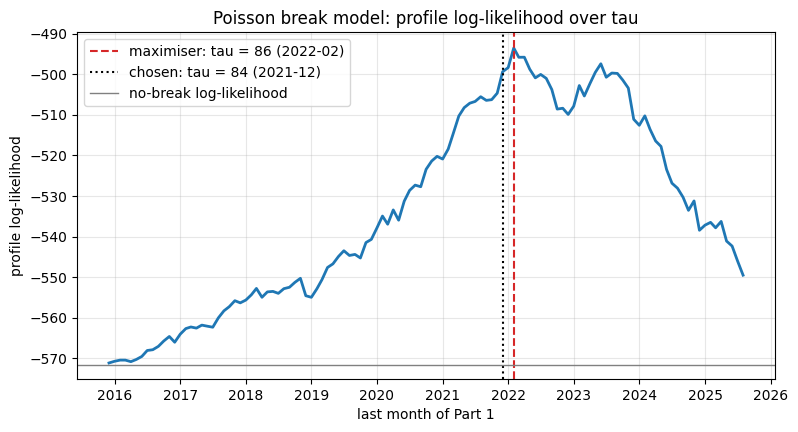

tau* = 86 (2022-02), max log-lik = -493.53, log-lik at tau = 84: -499.39


In [14]:
def break_analysis(tau):
    """Items 5(a)-(c) for a given tau; returns one row of the sensitivity table."""
    a, b = y[:tau], y[tau:]
    lr_p = 2 * (ll_poisson(a) + ll_poisson(b) - ll_poisson(y))
    lr_n = 2 * (ll_normal(a) + ll_normal(b) - ll_normal(y))
    return {"tau": tau, "last month of Part 1": f"{dates[tau-1]:%Y-%m}",
            "mu1 = lambda1": a.mean(), "mu2 = lambda2": b.mean(),
            "sigma2_1": a.var(ddof=0), "sigma2_2": b.var(ddof=0),
            "LR Poisson": lr_p, "p Poisson": chi2.sf(lr_p, 1),
            "LR Normal (df=2)": lr_n, "p Normal": chi2.sf(lr_n, 2),
            "Welch p": stats.ttest_ind(a, b, equal_var=False).pvalue}


sens = pd.DataFrame([break_analysis(tt) for tt in [60, 70, 72, 84, 86, 96, 108]]).set_index("tau")
for c in ["mu1 = lambda1", "mu2 = lambda2", "sigma2_1", "sigma2_2", "LR Poisson", "LR Normal (df=2)"]:
    sens[c] = sens[c].map("{:.2f}".format)
for c in ["p Poisson", "p Normal", "Welch p"]:
    sens[c] = sens[c].map("{:.1e}".format)
display(sens)

# profile log-likelihood of the Poisson break model, at least 12 months in each part
taus = np.arange(12, n - 11)
prof = np.array([ll_poisson(y[:tt]) + ll_poisson(y[tt:]) for tt in taus])
tau_star = taus[prof.argmax()]

fig, ax = plt.subplots()
ax.plot(dates[taus - 1], prof, lw=2)
ax.axvline(dates[tau_star - 1], color="C3", ls="--", label=f"maximiser: tau = {tau_star} ({dates[tau_star-1]:%Y-%m})")
ax.axvline(dates[tau - 1], color="k", ls=":", label=f"chosen: tau = {tau} ({dates[tau-1]:%Y-%m})")
ax.axhline(ll_poisson(y), color="grey", lw=1, label="no-break log-likelihood")
ax.set_xlabel("last month of Part 1")
ax.set_ylabel("profile log-likelihood")
ax.set_title("Poisson break model: profile log-likelihood over tau")
ax.legend()
plt.show()
print(f"tau* = {tau_star} ({dates[tau_star-1]:%Y-%m}), max log-lik = {prof.max():.2f}, "
      f"log-lik at tau = {tau}: {prof[taus == tau][0]:.2f}")

### Answer 5(d)

**Result:** yes, the break is confirmed. For every $\tau$ tried (Dec 2019, Oct 2020, Dec 2020, Dec 2021, Feb 2022, Dec 2022, Dec 2023) all tests reject equality with p-values below $10^{-5}$. The existence of the break does not depend on $\tau$; its size does.

- Existence: The Poisson LR goes from 61.7 ($\tau = 60$) to 156.0 ($\tau = 86$); the normal LR from 30.1 to 69.5. All are far above the critical values (3.84 for df = 1, 5.99 for df = 2).
- Best break point: The profile log-likelihood is highest at $\tau = 86$ (February 2022), with $\ell = -493.53$, against $-499.39$ at our $\tau = 84$. The curve climbs steadily from 2016 to early 2022, so the data clearly place the main change there. It has a second, slightly lower peak at $\tau = 102$ (June 2023, $\ell = -497.42$), where the split separates 2015 to mid-2023 (mean 27.3) from the highest months (mean 40.6). Two peaks this close in height are what a single-break model produces when the level rises in more than one step or gradually, which is the case in Part 2.
- Size of the jump: $\hat\lambda_1$ is stable (26.2 to 28.0) for every $\tau$, as expected if the rate before 2022 was roughly constant. $\hat\lambda_2$ increases steadily with $\tau$, from 34.1 ($\tau = 60$) to 40.7 ($\tau = 108$), so the estimated jump $\hat\lambda_2 - \hat\lambda_1$ goes from 7.4 to 12.7. Moving the cut later drops the early, lower months of the second regime, which means the level keeps rising after the break. A single step does not describe Part 2 well; Question 6 models this trend.
- Breaks too early: Cutting at Dec 2019 or Oct 2020 (the midpoint of the series) puts several 2020 and 2021 months in Part 2 and lowers both the LR and the jump, consistent with the break being later than 2020.

In [15]:
def dispersion_row(x):
    """Mean, variance, variance/mean and the chi2(n-1) dispersion test for a count sample."""
    m, v = x.mean(), x.var(ddof=1)
    D = np.sum((x - m) ** 2) / m
    return {"n": len(x), "mean": m, "variance": v, "variance/mean": v / m, "p-value": chi2.sf(D, len(x) - 1)}


disp = pd.DataFrame({"full sample": dispersion_row(y),
                     "Part 1": dispersion_row(y1),
                     "Part 2": dispersion_row(y2)}).T
display(disp.assign(n=disp["n"].astype(int), **{"p-value": disp["p-value"].map("{:.1e}".format)}).round(2))

# same ratio with December removed, to see how much of the dispersion is the December peak
not_dec = dates.month != 12
print("variance/mean without Decembers: Part 1 = {:.2f}, Part 2 = {:.2f}".format(
    y1[not_dec[:tau]].var(ddof=1) / y1[not_dec[:tau]].mean(),
    y2[not_dec[tau:]].var(ddof=1) / y2[not_dec[tau:]].mean()))

,n,mean,variance,variance/mean,p-value
full sample,140,30.91,92.25,2.98,3.1e-29
Part 1,84,26.26,50.80,1.93,7.1e-07
Part 2,56,37.89,73.84,1.95,3.2e-05


variance/mean without Decembers: Part 1 = 1.62, Part 2 = 1.68


### Answer 5(e)

**Result:** the overdispersion falls but does not disappear. Variance/mean goes from 2.98 in the full sample to 1.93 in Part 1 and 1.95 in Part 2. Both are still significantly above 1 (dispersion test p-values $7\times10^{-7}$ and $3\times10^{-5}$).

| | n | mean | variance | variance/mean |
|---|---|---|---|---|
| full sample | 140 | 30.91 | 92.25 | 2.98 |
| Part 1 | 84 | 26.26 | 50.80 | 1.93 |
| Part 2 | 56 | 37.89 | 73.84 | 1.95 |

Interpretation:
- Part of the overdispersion came from mixing two regimes: If the rate is $\lambda_1$ in some months and $\lambda_2$ in others, the pooled variance is the average within-part variance plus the variance of the rate: $V(y) = E[V(y\mid\text{part})] + V(E[y\mid\text{part}])$. With the MLE variances: $\frac{84 \times 50.19 + 56 \times 72.52}{140} = 59.1$ within, plus $\frac{84}{140}\cdot\frac{56}{140}(37.89-26.26)^2 = 32.5$ between, which gives back the total 91.6. About 35% of the total variance is the difference between the two regimes.
- **The rest comes from variation inside each part** that a constant-rate Poisson cannot capture: the December peak (removing the Decembers lowers the ratio to 1.62 and 1.68), the upward trend in Part 2, and irregular months such as 2020. A Poisson model with a rate that depends on the season and on time, or a negative binomial model, would be needed to remove it.

---
## Question 6 (optional): Time-varying rate in Part 2, $y_{\tau+s} \sim \text{Poisson}(\lambda_0 + \lambda_1 s)$

*Part 1 keeps a constant rate; in Part 2 the rate is linear in $s$, the number of months after the break. (a) Log-likelihood and parameter restriction. (b) MLEs and standard errors. (c) Test $H_0: \lambda_1 = 0$ vs $H_1: \lambda_1 > 0$; compare with 5(b). (d) Linear rate in Part 1. (e) Fitted rates over the plot of Question 4. (f) Log-linear vs linear specification.*

Throughout, $\tau = 84$ and $m = n - \tau = 56$.

### Answer 6(a)

**Result:**
$$\ell(\lambda_0,\lambda_1) = \sum_{s=1}^{m}\Big[\, y_{\tau+s}\log(\lambda_0+\lambda_1 s) - (\lambda_0+\lambda_1 s) - \log y_{\tau+s}! \,\Big], \qquad m = n-\tau = 56,$$
and the parameters must satisfy $\lambda_0 + \lambda_1 s > 0$ for every $s = 1,\dots,m$.

The Poisson rate must be positive in every month, otherwise $\log(\lambda_0+\lambda_1 s)$ is not defined. Because the rate is linear in $s$, it is enough to check the two ends of the sample: $\lambda_0 + \lambda_1 > 0$ and $\lambda_0 + \lambda_1 m > 0$. When $\lambda_1 \ge 0$ this reduces to $\lambda_0 + \lambda_1 > 0$. In the optimisation the negative log-likelihood is set to $+\infty$ outside this region.

Score and observed information (used for the standard errors in 6(b)), with $\lambda_s = \lambda_0+\lambda_1 s$ and $x_s = (1, s)'$:
$$\frac{\partial \ell}{\partial(\lambda_0,\lambda_1)'} = \sum_{s=1}^m \left(\frac{y_{\tau+s}}{\lambda_s} - 1\right) x_s, \qquad J(\lambda_0,\lambda_1) = -\frac{\partial^2 \ell}{\partial\theta\,\partial\theta'} = \sum_{s=1}^m \frac{y_{\tau+s}}{\lambda_s^2}\, x_s x_s'.$$

In [16]:
def fit_linear_poisson(x):
    """MLE of Poisson(b0 + b1*s), s = 1..len(x), by numerical optimisation.

    Returns (theta_hat, se, max log-lik). The standard errors come from the analytic
    observed information sum(x_s / rate_s^2 * [1, s][1, s]'), evaluated at the optimum.
    """
    s_ = np.arange(1, len(x) + 1)

    def negll(theta):
        rate = theta[0] + theta[1] * s_
        if np.any(rate <= 0):
            return np.inf
        return -poisson.logpmf(x, rate).sum()

    res = minimize(negll, x0=[x.mean(), 0.0], method="Nelder-Mead",
                   options={"xatol": 1e-8, "fatol": 1e-10, "maxiter": 5000})
    rate = res.x[0] + res.x[1] * s_
    X = np.column_stack([np.ones_like(s_), s_])
    obs_info = (X * (x / rate**2)[:, None]).T @ X
    se = np.sqrt(np.diag(np.linalg.inv(obs_info)))
    return res.x, se, -res.fun


s = np.arange(1, n2 + 1)
theta2, se2, ll_lin2 = fit_linear_poisson(y2)
lam0_hat, lam1_hat = theta2

glm2 = sm.GLM(y2, sm.add_constant(s), family=sm.families.Poisson(link=sm.families.links.Identity())).fit()

pd.DataFrame({"optimiser": theta2, "se (observed info)": se2,
              "GLM identity link": glm2.params, "GLM se": glm2.bse},
             index=["lambda0", "lambda1"]).round(4)

C:\Users\pedro\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:308: DomainWarning: The Identity link function does not respect the domain of the Poisson family.
  warnings.warn((f"The {type(family.link).__name__} link function "


,optimiser,se (observed info),GLM identity link,GLM se
lambda0,31.495,1.598,31.495,1.593
lambda1,0.225,0.051,0.225,0.051


### Answer 6(b)

**Result:** $\hat\lambda_0 = 31.50$ (se 1.60) and $\hat\lambda_1 = 0.225$ (se 0.051).

The estimates come from Nelder-Mead on the negative log-likelihood, starting at $(\bar y_2, 0)$; standard errors are the square roots of the diagonal of $J(\hat\lambda_0,\hat\lambda_1)^{-1}$. The statsmodels GLM with Poisson family and identity link gives the same estimates. Its standard errors differ only in the third decimal (1.593 vs 1.598) because the GLM uses the expected information $\sum_s x_s x_s'/\lambda_s$ instead of the observed one; the two agree in expectation. The warning printed by statsmodels is about the identity link not guaranteeing a positive rate, which is exactly the restriction in 6(a); it is satisfied at the estimates.

Interpretation: the expected number of deaths rises by about 0.22 per month, or about 2.7 per year. The fitted rate goes from 31.7 in January 2022 ($s = 1$) to 44.1 in August 2026 ($s = 56$).

In [17]:
z = lam1_hat / se2[1]
LR_trend2 = 2 * (ll_lin2 - ll_poisson(y2))
aic_const2 = -2 * ll_poisson(y2) + 2 * 1
aic_lin2 = -2 * ll_lin2 + 2 * 2

pd.Series({"lambda1_hat": lam1_hat, "Wald z": z, "one-sided p (Wald)": norm.sf(z),
           "LR vs constant rate": LR_trend2, "one-sided p (LR, chi2_1 / 2)": chi2.sf(LR_trend2, 1) / 2,
           "AIC constant rate (item 5b)": aic_const2, "AIC linear rate": aic_lin2}).to_frame("Part 2").map(lambda v: f"{v:.4g}")

,Part 2
lambda1_hat,0.2245
Wald z,4.408
one-sided p (Wald),5.214e-06
LR vs constant rate,19.35
"one-sided p (LR, chi2_1 / 2)",5.454e-06
AIC constant rate (item 5b),417.3
AIC linear rate,399.9


### Answer 6(c)

**Result:** reject $H_0: \lambda_1 = 0$ in favour of $\lambda_1 > 0$. The death rate is increasing within Part 2.

- Wald test: $z = 0.2245/0.0509 = 4.41$, one-sided $p = 5\times10^{-6}$.
- LR test against the constant-rate Part 2 model of 5(b): $LR = 19.35$. Under $H_0$ it is $\chi^2_1$; for the one-sided alternative the p-value is halved: $p = 5\times10^{-6}$.
- AIC: constant rate 417.3, linear rate 399.9. The linear model is better by 17 points.

Even after inflating the standard error by $\sqrt{1.95}$ to account for the overdispersion found in 5(e), $z \approx 3.2$ and the trend stays significant at 1%.

In [18]:
theta1, se1, ll_lin1 = fit_linear_poisson(y1)
z1 = theta1[1] / se1[1]
LR_trend1 = 2 * (ll_lin1 - ll_poisson(y1))

pd.Series({"beta0_hat": theta1[0], "se(beta0)": se1[0], "beta1_hat": theta1[1], "se(beta1)": se1[1],
           "Wald z": z1, "two-sided p (Wald)": 2 * norm.sf(abs(z1)),
           "LR vs constant rate": LR_trend1, "p (LR, chi2_1)": chi2.sf(LR_trend1, 1),
           "AIC constant": -2 * ll_poisson(y1) + 2, "AIC linear": -2 * ll_lin1 + 4}).to_frame("Part 1").map(lambda v: f"{v:.4g}")

,Part 1
beta0_hat,27.61
se(beta0),1.134
beta1_hat,-0.0317
se(beta1),0.02282
Wald z,-1.389
two-sided p (Wald),0.1648
LR vs constant rate,1.929
"p (LR, chi2_1)",0.1649
AIC constant,585.5
AIC linear,585.6


### Answer 6(d)

**Result:** yes, a constant rate before the break is reasonable. In Part 1, $\hat\beta_0 = 27.61$ (se 1.13) and $\hat\beta_1 = -0.032$ (se 0.023). The slope is small, slightly negative and not significant: Wald $z = -1.39$, $p = 0.16$; LR $= 1.93$, $p = 0.16$.

AIC is 585.5 for the constant rate and 585.6 for the linear rate, so the extra parameter does not improve the fit. Over the 84 months of Part 1 the fitted slope would change the rate by only $-0.032 \times 84 \approx -2.7$ deaths, which matches the flat moving average for 2015 to 2021 in Question 4.

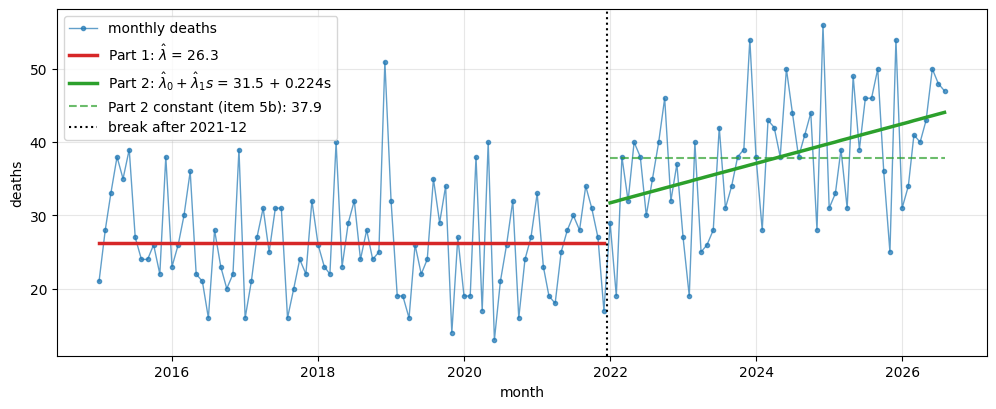

fitted Part 2 rate: 31.7 in 2022-01, 44.1 in 2026-08


In [19]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ys.index, ys, "o-", ms=3, lw=1, color="C0", alpha=0.7, label="monthly deaths")
ax.plot(dates[:tau], np.full(tau, lam1), lw=2.5, color="C3", label=rf"Part 1: $\hat\lambda$ = {lam1:.1f}")
ax.plot(dates[tau:], lam0_hat + lam1_hat * s, lw=2.5, color="C2",
        label=rf"Part 2: $\hat\lambda_0+\hat\lambda_1 s$ = {lam0_hat:.1f} + {lam1_hat:.3f}s")
ax.plot(dates[tau:], np.full(n2, lam2), lw=1.5, ls="--", color="C2", alpha=0.7,
        label=rf"Part 2 constant (item 5b): {lam2:.1f}")
ax.axvline(dates[tau] - pd.Timedelta(days=15), color="k", ls=":", label=f"break after {dates[tau-1]:%Y-%m}")
ax.set_xlabel("month")
ax.set_ylabel("deaths")
ax.legend(loc="upper left")
plt.show()

print(f"fitted Part 2 rate: {lam0_hat + lam1_hat:.1f} in {dates[tau]:%Y-%m}, {lam0_hat + lam1_hat * n2:.1f} in {dates[-1]:%Y-%m}")

### Answer 6(e)

**Result:** the combined model describes the series much better than a single step. Part 1 is flat at $\hat\lambda = 26.3$. At the break the rate jumps to 31.7 and then increases linearly to 44.1 by August 2026.

- The model has both a level shift and a trend: the first fitted value of Part 2 (31.7) is already 5.5 deaths above the Part 1 rate, and the trend adds another 12.4 deaths over the following 55 months.
- The constant Part 2 rate of 5(b) (dashed line, 37.9) overestimates the start of Part 2 (2022, observed mean 34.7) and underestimates the end (2024 to 2026, around 40 to 42). The linear rate corrects both.
- What the model still misses: the December peaks sit well above the fitted line (Dec 2023, 2024, 2025), and months such as Feb 2022 (19), Feb 2023 (19) or Nov 2025 (25) sit well below it. These are the seasonal pattern and the overdispersion that remain within each part. A seasonal term (for example a December dummy) would be the next step.
- The linear trend should not be extrapolated far: the moving average in Question 4 suggests the rise slowed down after 2024.

In [20]:
# (f) log-linear alternative on Part 2: log rate = beta0 + beta1*s (canonical log link)
glm_log2 = sm.GLM(y2, sm.add_constant(s), family=sm.families.Poisson()).fit()
b0, b1 = glm_log2.params
pd.Series({"beta0": b0, "beta1": b1, "se(beta1)": glm_log2.bse[1],
           "monthly growth exp(beta1)-1": np.exp(b1) - 1, "annual growth exp(12 beta1)-1": np.exp(12 * b1) - 1,
           "log-lik": glm_log2.llf, "AIC log-linear": glm_log2.aic, "AIC linear (item 6b)": aic_lin2}).to_frame("Part 2").map(lambda v: f"{v:.4g}")

,Part 2
beta0,3.462
beta1,0.005886
se(beta1),0.001347
monthly growth exp(beta1)-1,0.005903
annual growth exp(12 beta1)-1,0.07318
log-lik,-198.1
AIC log-linear,400.1
AIC linear (item 6b),399.9


### Answer 6(f)

**Result:** over this sample both specifications fit equally well (AIC 400.1 for log-linear and 399.9 for linear). The log-linear model is more convenient and safer to estimate; the linear model is easier to read and extrapolates more conservatively.

Fitted log-linear model: $\hat\beta_1 = 0.00589$ (se 0.00135), so the rate grows about 0.59% per month, or 7.3% per year. Over 56 months an exponential with such a small growth rate is almost a straight line, which is why the two fits are so close.

Advantages of $\log\lambda_s = \beta_0 + \beta_1 s$:
- The rate $e^{\beta_0+\beta_1 s}$ is always positive, so there is no restriction on the parameters and no risk of a negative rate in estimation or forecasting.
- The log is the canonical link of the Poisson. The log-likelihood is globally concave, the standard GLM algorithm (IRLS) converges reliably, and expected and observed information coincide.
- Effects are multiplicative: $e^{\beta_1}$ is a rate ratio and $100(e^{\beta_1}-1)$ a percentage change per month. Other covariates, such as a December dummy, then act as proportional effects, which fits a peak that grows with the level of the series.

Disadvantages:
- The trend is exponential. Over long horizons it grows without bound, and forecasts can become unrealistic faster than with a linear trend.
- $\beta_1$ is not in deaths per month; to get the effect in deaths it has to be converted, and that effect depends on $s$.
- If the true increase is additive (a fixed number of extra deaths per month), the log-linear model is misspecified, and that shows up over longer samples.

---
## Summary of answers

| Item | Answer |
|---|---|
| 1 | Mean 30.91, median 30, variance 92.25, s.d. 9.60; mildly right-skewed, flat histogram, highest months are Decembers, no outliers by the IQR rule |
| 2(a) | $\hat\mu = \bar y$, $\hat\sigma^2 = \frac1n\sum(y_t-\bar y)^2$ |
| 2(b) | $\hat\mu = 30.91$, $\hat\sigma^2 = 91.59$; 95% CI for $\mu$: $[29.31, 32.52]$ |
| 2(c) | Poor fit (Shapiro-Wilk $p = 0.007$); ignores integer counts, mean-variance link, skewness and time structure |
| 3(a) | $\hat\lambda = \bar y$, $\text{se} = \sqrt{\hat\lambda/n}$ from $I(\lambda) = n/\lambda$ |
| 3(b) | $\hat\lambda = 30.91$, se 0.47, 95% CI $[29.99, 31.84]$ |
| 3(c) | Poisson far too concentrated: tails 0.136 observed vs 0.025 and 0.033 predicted |
| 3(d) | Strong overdispersion: variance/mean $= 2.98$, $p \approx 10^{-29}$; Poisson se too small |
| 3(e) | Gaussian preferred: AIC 1033.7 vs 1145.0 (Poisson) |
| 4 | Not i.i.d.: flat level to 2021, jump in 2022, rise to about 40 by 2024; December peak; lag-1 autocorrelation 0.38 |
| 5 | $\tau = 84$ (Dec 2021). $\hat\mu_1 = \hat\lambda_1 = 26.26$, $\hat\mu_2 = \hat\lambda_2 = 37.89$; $\hat\sigma_1^2 = 50.19$, $\hat\sigma_2^2 = 72.52$ |
| 5(c) | Break rejected as absent: Poisson LR 144.3 (df 1), normal LR 63.6 (df 2), all $p < 10^{-12}$ |
| 5(d) | Break confirmed for every $\tau$ tried; best $\tau = 86$ (Feb 2022); the jump size grows with $\tau$ (trend in Part 2) |
| 5(e) | Variance/mean falls to 1.93 and 1.95; about 35% of the variance was the regime difference; the rest is seasonality and trend |
| 6(b) | $\hat\lambda_0 = 31.50$ (1.60), $\hat\lambda_1 = 0.225$ (0.051) |
| 6(c) | $\lambda_1 > 0$: $z = 4.41$, LR 19.35, one-sided $p \approx 5\times10^{-6}$; AIC 399.9 vs 417.3 |
| 6(d) | Part 1 slope $-0.032$ (0.023), $p = 0.16$: constant rate is reasonable |
| 6(e) | Flat 26.3, jump to 31.7, linear rise to 44.1; December peaks still unexplained |
| 6(f) | Log-linear: +0.59% per month, AIC 400.1 vs 399.9; positivity and canonical link vs exponential extrapolation |